In [3]:

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. INPUT FILES
# --------------------------------------------------
grid_path = r"data/grid_overall_biodiversity.gpkg"
refugia_path = r"data/Congo_Basin_Pleistocene_refugia_maley96.gpkg"

output_gpkg = r"data/grid_refugia_distance.gpkg"
output_csv = r"data/grid_refugia_distance.csv"

# --------------------------------------------------
# 2. LOAD DATA
# --------------------------------------------------
grid = gpd.read_file(grid_path)
refugia = gpd.read_file(refugia_path)

# Replace with the actual unique identifier in your grid
grid_id = "grid"

if grid_id not in grid.columns:
    raise ValueError(
        f"'{grid_id}' not found. Set grid_id to your actual grid ID column."
    )

if grid[grid_id].isna().any():
    raise ValueError("Some grid cells have missing IDs.")

if grid[grid_id].duplicated().any():
    raise ValueError("Grid IDs must be unique.")

if grid.crs is None or refugia.crs is None:
    raise ValueError("Both layers must have a defined CRS.")

# --------------------------------------------------
# 3. REPROJECT TO A METRIC CRS
# --------------------------------------------------
# Example: Africa Albers Equal Area.
# Check its distance distortion for your study area.
metric_crs = "ESRI:102022"

grid = grid.to_crs(metric_crs)
refugia = refugia.to_crs(metric_crs)

# Remove empty or missing geometries
grid = grid[
    grid.geometry.notna() & ~grid.geometry.is_empty
].copy()

refugia = refugia[
    refugia.geometry.notna() & ~refugia.geometry.is_empty
].copy()

if refugia.empty:
    raise ValueError("No valid refugia geometries found.")

# Repair invalid geometries where possible
refugia["geometry"] = refugia.geometry.make_valid()

# Dissolve overlapping refugia into a single geometry.
# This avoids treating overlapping polygons as separate regions.
refugia_union = refugia.geometry.union_all()

# --------------------------------------------------
# 4. CALCULATE GRID CENTROIDS
# --------------------------------------------------
grid["centroid"] = grid.geometry.centroid

# --------------------------------------------------
# 5. DISTANCE TO NEAREST REFUGIUM BOUNDARY
# --------------------------------------------------
# Distance is measured from each centroid to the
# nearest point on the boundary of any refugium polygon.
refugia_boundary = refugia_union.boundary

grid["refugia_dist_km"] = (
    grid["centroid"].distance(refugia_boundary) / 1000
)

# --------------------------------------------------
# 6. OPTIONAL: DISTANCE FROM GRID POLYGON ITSELF
# --------------------------------------------------
# Cells intersecting a refugium receive distance zero.
grid["refugia_polygon_dist_km"] = (
    grid.geometry.distance(refugia_union) / 1000
)

# --------------------------------------------------
# 7. SAVE RESULTS
# --------------------------------------------------
# Remove temporary centroid geometry before saving.
grid = grid.drop(columns=["centroid"])

grid.to_file(
    output_gpkg,
    layer="grid_refugia_distance",
    driver="GPKG"
)

# CSV with attributes only
grid.drop(columns="geometry").to_csv(
    output_csv, index=False
)

print("Distance calculation completed.")
print("Number of grid cells:", len(grid))
print(grid[
    [grid_id, "refugia_dist_km", "refugia_polygon_dist_km"]
].head())

print("\nDistance summary (km):")
print(grid["refugia_dist_km"].describe())

Distance calculation completed.
Number of grid cells: 114947
   grid  refugia_dist_km  refugia_polygon_dist_km
0   308        51.947058                51.096497
1   309        51.159376                50.728262
2   318        51.917624                51.447963
3   319        53.808728                51.851205
4   320        56.043009                53.187480

Distance summary (km):
count    114947.000000
mean        181.200548
std         152.675223
min           0.001080
25%          50.631569
50%         149.572109
75%         276.771737
max         683.629293
Name: refugia_dist_km, dtype: float64


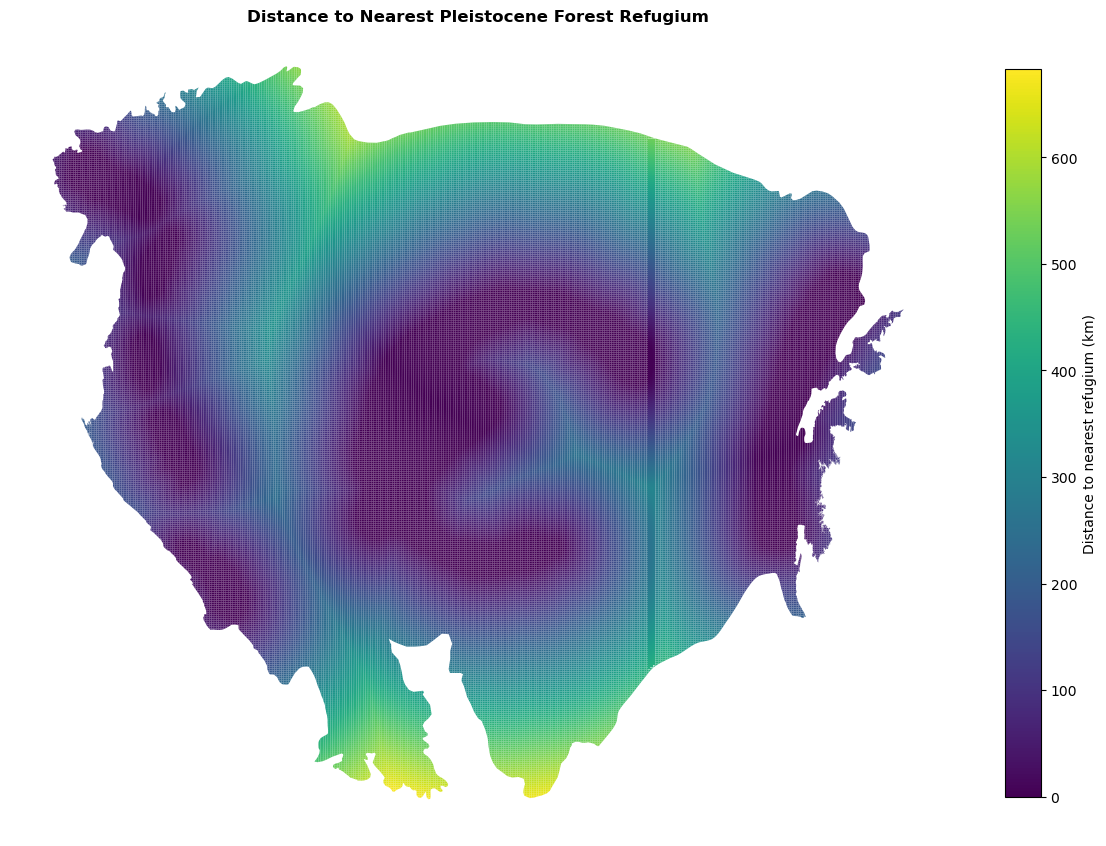

In [6]:

fig, ax = plt.subplots(figsize=(12, 10))

grid.plot(
    column="refugia_dist_km",
    ax=ax,
    legend=True,
    cmap="viridis",
    edgecolor="none",
    legend_kwds={
        "label": "Distance to nearest refugium (km)",
        "shrink": 0.75
    }
)

ax.set_title(
    "Distance to Nearest Pleistocene Forest Refugium",
    fontweight="bold"
)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(
    "refugia_distance_map.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()